# T06 · Auto-encodeurs & modèles de représentation — DL/RL appliqués à la cybersécurité

**Objectifs du cours :**
- Construire un auto-encodeur en numpy pur (encodeur, goulot, décodeur, perte MSE) et l'entraîner à la main
- Comprendre le théorème AE linéaire = PCA et le rôle régularisant du débruitage (Goodfellow ch. 14)
- Transformer l'erreur de reconstruction en score d'anomalie calibré (seuil, ROC, AUC) et exploiter le latent pour la similarité

**Pourquoi c'est fondamental en cyber :**

| Besoin cyber | Outil |
|---|---|
| Presque pas d'attaques étiquetées (non supervisé) | AE entraîné sur le trafic bénin uniquement |
| Comportements « hors norme » | Erreur de reconstruction = score d'anomalie |
| Alerte SOC calibrée | Seuil = quantile du score bénin → FPR contrôlé |
| Tri des alertes, similarité d'attaques | k-NN dans l'espace latent |

**Prérequis :** T01 (backprop d'un MLP), T02 (gradient, sur-apprentissage),
T03 (optimiseurs — on utilise Adam), algèbre linéaire (PCA, projection).

> **Conseil d'étude :** sachez refaire l'exercice P2 (AE linéaire = PCA) —
> c'est LA question de cours qui relie ce chapitre au cours d'algèbre.

## 📌 Bloc 0 — Environnement & imports
Installez le stack si besoin (déjà pré-installé sur Colab).
Le notebook contient des sorties pré-calculées : relisibles sans rien exécuter,
ou « Run All » pour reproduire (numpy pur, graines figées, aucune donnée réseau).

In [1]:
!pip install -q numpy scipy pandas matplotlib scikit-learn
# Block 0 — environment & imports (the builder prepends the !pip line for the notebook)
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve

np.set_printoptions(precision=3, suppress=True, linewidth=100)
print("numpy", np.__version__)

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

numpy 2.5.4


## 1 · L'auto-encodeur : encodage, goulot, reconstruction

Un **auto-encodeur (AE)** apprend à recopier son entrée sur sa sortie en
passant par une représentation forcée à être **compacte** :

```
h = tanh(W₁·x + b₁)        encodeur
z = W₂·h + b₂              GOULOT (bottleneck), k < dim(x)
h' = tanh(W₃·z + b₃)       décodeur
x̂ = W₄·h' + b₄             reconstruction
Perte : L = MSE(x̂, x)
```

Le goulot `k` est **plus petit** que la dimension d'entrée : le réseau ne
peut pas mémoriser passivement, il est obligé d'apprendre une **représentation
compacte** des données — le « résumé » utile.

**Piège classique :** goulot trop grand (k ≥ dim) → l'AE apprend la fonction
identité sans rien représenter : l'erreur est nulle **y compris sur les
anomalies**, qui ne sont plus détectables. Le goulot doit être *étroit*.

In [2]:
# Demo 1 — AE implemented fully by hand (numpy), trained with Adam
def ae_forward(X, P):
    """Forward pass. P = [W1,b1,W2,b2,W3,b3,W4,b4] (d->h->k->h->d)."""
    W1, b1, W2, b2, W3, b3, W4, b4 = P
    a1 = np.tanh(X @ W1 + b1)          # encoder hidden
    z = a1 @ W2 + b2                   # bottleneck (linear)
    a3 = np.tanh(z @ W3 + b3)          # decoder hidden
    xhat = a3 @ W4 + b4                # reconstruction (linear)
    return xhat, (a1, z, a3)

def ae_mse(X, P):
    xhat, _ = ae_forward(X, P)
    return np.mean((xhat - X) ** 2)

def ae_train(X, d, h, k, epochs=600, lr=0.05, seed=0):
    """Full-batch Adam training of the AE on X (n, d); returns params P."""
    rng = np.random.default_rng(seed)
    s = lambda a, b: 0.5 * np.sqrt(6.0 / (a + b))
    P = [rng.normal(0, s(d, h), (d, h)), np.zeros(h),
         rng.normal(0, s(h, k), (h, k)), np.zeros(k),
         rng.normal(0, s(k, h), (k, h)), np.zeros(h),
         rng.normal(0, s(h, d), (h, d)), np.zeros(d)]
    mP = [np.zeros_like(p) for p in P]; vP = [np.zeros_like(p) for p in P]
    b1_, b2_, eps_, t = 0.9, 0.999, 1e-8, 0
    n = X.shape[0]
    for ep in range(epochs):
        xhat, (a1, z, a3) = ae_forward(X, P)
        W1, bb1, W2, bb2, W3, bb3, W4, bb4 = P
        d_out = 2.0 * (xhat - X) / n                    # dL/dxhat (mean-MSE)
        gW4 = a3.T @ d_out; gb4 = d_out.sum(0)
        da3 = d_out @ W4.T; dpre3 = da3 * (1 - a3 ** 2)
        gW3 = z.T @ dpre3; gb3 = dpre3.sum(0)
        dz = dpre3 @ W3.T
        gW2 = a1.T @ dz; gb2 = dz.sum(0)
        da1 = dz @ W2.T; dpre1 = da1 * (1 - a1 ** 2)
        gW1 = X.T @ dpre1; gb1 = dpre1.sum(0)
        G = [gW1, gb1, gW2, gb2, gW3, gb3, gW4, gb4]
        t += 1
        for i, p in enumerate(P):
            mP[i] = b1_ * mP[i] + (1 - b1_) * G[i]
            vP[i] = b2_ * vP[i] + (1 - b2_) * G[i] ** 2
            p -= lr * (mP[i] / (1 - b1_ ** t)) / (np.sqrt(vP[i] / (1 - b2_ ** t)) + eps_)
    return P

# Synthetic flows: low-rank manifold (3 latent factors) + noise, d=8 features
def make_benign(rng, n):
    Z = rng.normal(0, 1, (n, 3))
    P0 = np.array([[1.0, 0.3, 0.0, 0.5, 0.2, 0.1, 0.0, 0.4],
                   [0.0, 1.0, 0.2, 0.1, 0.6, 0.3, 0.1, 0.0],
                   [0.4, 0.0, 1.0, 0.2, 0.0, 0.5, 0.3, 0.2]])
    return Z @ P0 + rng.normal(0, 0.15, (n, 8))

def make_attacks(rng, n):
    """3 attack families off the benign manifold (60 flows each family)."""
    Z = rng.normal(0, 1, (3 * n, 3))
    P0 = np.array([[1.0, 0.3, 0.0, 0.5, 0.2, 0.1, 0.0, 0.4],
                   [0.0, 1.0, 0.2, 0.1, 0.6, 0.3, 0.1, 0.0],
                   [0.4, 0.0, 1.0, 0.2, 0.0, 0.5, 0.3, 0.2]])
    base = Z @ P0 + rng.normal(0, 0.15, (3 * n, 8))
    ddos = base[:n].copy(); ddos[:, 3] += 6.0; ddos[:, 0] += 3.5     # bytes_out massif
    scan = base[n:2*n].copy(); scan[:, 4] += 4.0; scan[:, 5] -= 3.0  # balayage de ports
    exfil = base[2*n:].copy(); exfil[:, 7] += 5.0; exfil[:, 1] += 2.5  # burst sortant
    return np.vstack([ddos, scan, exfil]), np.r_[np.full(n, 0), np.full(n, 1), np.full(n, 2)]

rng = np.random.default_rng(0)
Xben = make_benign(rng, 400)
Xben = (Xben - Xben.mean(0)) / Xben.std(0)            # standardized features
# attack set (points 4-6) + a second benign set standardized on its own stats
rngA = np.random.default_rng(101)
Xatk_raw, labatk = make_attacks(rngA, 60)
Xben9 = make_benign(rngA, 300)
mu9, sd9 = Xben9.mean(0), Xben9.std(0)
Xben9 = (Xben9 - mu9) / sd9
Xatk = (Xatk_raw - mu9) / sd9                          # standardize on BENIGN stats
P_ae = ae_train(Xben, d=8, h=5, k=2, epochs=600, seed=1)
mse0 = ae_mse(Xben, [np.zeros_like(p) for p in P_ae])
mse1 = ae_mse(Xben, P_ae)
print(f"AE 8→5→2→5→8 sur {Xben.shape[0]} flux bénins standardisés")
print(f"MSE reconstruction : init = {mse0:.4f} → entraîné = {mse1:.5f}")
xhat, (a1, z, a3) = ae_forward(Xben, P_ae)
assert mse1 < 0.25 * mse0, "l'AE doit effondrer l'erreur de reconstruction"
assert z.shape == (400, 2), "goulot = 2 dimensions (< 8)"
print(f"goulot z : {z.shape} — variance portées ~ 2 facteurs sur 8 dimensions")

AE 8→5→2→5→8 sur 400 flux bénins standardisés
MSE reconstruction : init = 1.0000 → entraîné = 0.22644
goulot z : (400, 2) — variance portées ~ 2 facteurs sur 8 dimensions


**Lecture.** Le goulot 2-dim ne peut encoder que la **structure dominante**
(les 3 facteurs latents sont eux-mêmes corrélés aux 8 features). Le reste —
bruit, et surtout **comportements inhabituels** — ne passera pas le goulot :
c'est exactement la propriété qu'on montera en score d'anomalie (point 4).

### Exercice corrigé

**P1 — Forward à la main.** Sur un mini-AE **linéaire** (d=3, goulot k=2,
sans tanh) avec des poids imposés (identité tronquée), recalculez `x̂` à la
main pour un vecteur `x` donné et comparez à la fonction. Vérifiez aussi que
reconstruire avec un goulot k=1 dégrade l'erreur sur un écart hors plan.

In [3]:
# ---- Exercice P1 : forward AE linéaire à la main + goulot qui dégrade ----
rng = np.random.default_rng(3)
def lin_ae_forward(x, W1, W2):
    z = x @ W1
    return z @ W2, z
W1 = np.array([[1., 0.], [0., 1.], [0., 0.]])          # projection sur (x1,x2)
W2 = W1.T                                                # tied weights
x_t = np.array([2.0, -1.0, 5.0])
xhat_t, z_t = lin_ae_forward(x_t, W1, W2)
xhat_manual = np.array([x_t[0], x_t[1], 0.0])           # par la formule, à la main
assert np.allclose(xhat_t, xhat_manual) and np.allclose(z_t, x_t[:2])
print("x =", x_t, "→ z =", z_t, "→ x̂ =", xhat_t, "(le goulot tue la 3e coord)")
err_k2 = np.sum((xhat_t - x_t) ** 2)
W1b = np.array([[1.], [0.], [0.]]); W2b = W1b.T         # goulot k=1
xhat_k1, _ = lin_ae_forward(x_t, W1b, W2b)
err_k1 = np.sum((xhat_k1 - x_t) ** 2)
print(f"erreur goulot k=2 : {err_k2:.1f} ; goulot k=1 : {err_k1:.1f}")
assert err_k1 > err_k2, "un goulot plus étroit reconstruit moins bien"
print("Exercice P1 vérifié ✔")

x = [ 2. -1.  5.] → z = [ 2. -1.] → x̂ = [ 2. -1.  0.] (le goulot tue la 3e coord)
erreur goulot k=2 : 25.0 ; goulot k=1 : 26.0
Exercice P1 vérifié ✔


## 2 · AE linéaire = PCA (lien valeurs propres)

**Théorème (Baldi & Hornik 1989 ; idéalement sous poids liés)** : le meilleur
auto-encodeur **linéaire** de rang `k` (au sens du MSE) projette les données
sur le sous-espace engendré par les `k` **premières composantes principales**
— les vecteurs propres de plus grandes valeurs propres de la covariance
`XᵀX`. L'erreur de reconstruction minimale vaut la somme des valeurs propres
restantes.

```
min_W ‖X − XWᵀW‖²  atteint en  W = P_k (top-k eigenvectors de la covariance)
MSE* = (1/n) Σ_{j>k} λ_j · d ... (résidu des facteurs non modélisés)
```

**Conséquence :** un AE linéaire n'est rien de plus qu'une PCA *vue comme un
réseau de neurones*. La non-linéarité (tanh) est ce qui apporte la valeur
ajoutée des AE profonds.

**Piège classique :** oublier de **centrer** les données — la PCA centre,
pas l'AE. Sans centrage, l'AE linéaire converge vers un plan qui ne passe
pas par la moyenne et les sous-espaces divergent.

In [4]:
# Demo 2 — train a LINEAR AE and compare its subspace to sklearn PCA
def lin_ae_train(X, k, epochs=4000, lr=0.05, seed=7):
    """Linear AE X -> XW1 -> zW2 -> xhat, untied, Adam. Returns (W1, W2)."""
    n, d = X.shape
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 0.3 * np.sqrt(6.0 / (d + k)), (d, k))
    W2 = rng.normal(0, 0.3 * np.sqrt(6.0 / (k + d)), (k, d))
    Ps = [W1, W2]; mP = [np.zeros_like(p) for p in Ps]; vP = [np.zeros_like(p) for p in Ps]
    b1_, b2_, eps_, t = 0.9, 0.999, 1e-8, 0
    for ep in range(epochs):
        z = X @ W1; xhat = z @ W2
        dout = 2.0 * (xhat - X) / n
        gW2 = z.T @ dout
        dz = dout @ W2.T
        gW1 = X.T @ dz
        t += 1
        for i, p in enumerate(Ps):
            G = [gW1, gW2][i]
            mP[i] = b1_ * mP[i] + (1 - b1_) * G
            vP[i] = b2_ * vP[i] + (1 - b2_) * G ** 2
            p -= lr * (mP[i] / (1 - b1_ ** t)) / (np.sqrt(vP[i] / (1 - b2_ ** t)) + eps_)
    return W1, W2

W1l, W2l = lin_ae_train(Xben, k=2, seed=7)
mse_lin_ae = np.mean((Xben @ W1l @ W2l - Xben) ** 2)
pca = PCA(n_components=2).fit(Xben)                    # data centered by sklearn
Xpca = pca.inverse_transform(pca.transform(Xben))
mse_pca = np.mean((Xpca - Xben) ** 2)
# subspace of the AE encoder = column space of W1 (left singular vectors)
U_ae, _, _ = np.linalg.svd(W1l)
E_ae = U_ae[:, :2]                                       # d x 2 orthonormal basis
# fraction of each PCA component captured by the AE subspace
capt = [np.linalg.norm(E_ae @ (E_ae.T @ pc)) for pc in pca.components_]
print(f"MSE AE linéaire = {mse_lin_ae:.5f}  vs  PCA(k=2) = {mse_pca:.5f}")
print(f"captura des composantes PCA par le sous-espace AE : {capt}")
print(f"valeurs propres PCA : {pca.explained_variance_}")
assert np.all([c > 0.99 for c in capt]), "l'AE linéaire retrouve le plan de PCA (>0.99)"
assert abs(mse_lin_ae - mse_pca) / mse_pca < 0.05, "erreurs de reconstruction quasi identiques"

MSE AE linéaire = 0.22907  vs  PCA(k=2) = 0.22907
captura des composantes PCA par le sous-espace AE : [np.float64(1.0000000000000002), np.float64(0.9999999999999999)]
valeurs propres PCA : [4.585 1.598]


### Exercice corrigé

**P2 — PCA retrouvée sur un plan connu.** On génère `X` sur le plan
`span(u₁, u₂)` (+ petit bruit), on entraîne un AE linéaire k=2, et on vérifie
que son sous-espace capture chaque direction vraie à **> 0.99** et que
`mse(AE) ≈ mse(PCA)` (±5 %).

In [5]:
# ---- Exercice P2 : AE linéaire sur un plan connu == projection PCA ----
rng = np.random.default_rng(11)
u1 = np.array([1., 1., 0., 0.]) / np.sqrt(2)
u2 = np.array([0., 0., 1., -1.]) / np.sqrt(2)
A = np.vstack([u1, u2])                                  # 2 x 4 : le plan vrai
Xplan = rng.normal(0, 1, (300, 2)) @ A + rng.normal(0, 0.05, (300, 4))
W1e, W2e = lin_ae_train(Xplan, k=2, epochs=4000, seed=13)
Ue, _, _ = np.linalg.svd(W1e)                            # column space of W1 = plan appris
Ee = Ue[:, :2]
cap_u1 = np.linalg.norm(Ee @ (Ee.T @ u1))
cap_u2 = np.linalg.norm(Ee @ (Ee.T @ u2))
mse_ae_e = np.mean((Xplan @ W1e @ W2e - Xplan) ** 2)
pc2 = PCA(n_components=2).fit(Xplan)
mse_pca_e = np.mean((pc2.inverse_transform(pc2.transform(Xplan)) - Xplan) ** 2)
print(f"capture de u1 = {cap_u1:.5f}, u2 = {cap_u2:.5f}")
print(f"MSE AE = {mse_ae_e:.5f} vs MSE PCA = {mse_pca_e:.5f}")
assert cap_u1 > 0.99 and cap_u2 > 0.99, "l'AE retrouve le plan vrai"
assert abs(mse_ae_e - mse_pca_e) / mse_pca_e < 0.05
print("Exercice P2 vérifié ✔")

capture de u1 = 0.99999, u2 = 0.99999
MSE AE = 0.00130 vs MSE PCA = 0.00130
Exercice P2 vérifié ✔


## 3 · Denoising & régularisation de l'AE

Le **denoising AE** (Vincent et al., 2008 — Goodfellow ch. 14) ne recopie pas
l'entrée : on **corruple** l'entrée `x̃ = x + bruit` et on cible la version
**propre** `x`.

```
entrée :  x̃ = x + σ·ε        cible : x        perte : MSE(D(E(x̃)), x)
```

L'AE ne peut plus apprendre l'identité : il est forcé de découvrir la
**structure du signal** pour « nettoyer ». Effets en cyber :
- robuste aux capteurs bruités / logs parcellaires ;
- régularisation implicite (comme le dropout) → moins de sur-apprentissage.

**Piège classique :** évaluer le débruitage en comparant la reconstruction à
l'entrée **corrompue** (toujours plus flatteur). L'objectif est `x` propre :
on compare `x̂` à `x`, pas à `x̃`.

In [6]:
# Demo 3 — train on corrupted inputs, target clean inputs; measure denoising
def ae_train_corrupted(Xcor, Xclean, d, h, k, epochs=600, lr=0.05, seed=0):
    """Train AE on corrupted inputs with CLEAN targets (denoising AE)."""
    rng = np.random.default_rng(seed)
    s = lambda a, b: 0.5 * np.sqrt(6.0 / (a + b))
    P = [rng.normal(0, s(d, h), (d, h)), np.zeros(h),
         rng.normal(0, s(h, k), (h, k)), np.zeros(k),
         rng.normal(0, s(k, h), (k, h)), np.zeros(h),
         rng.normal(0, s(h, d), (h, d)), np.zeros(d)]
    mP = [np.zeros_like(p) for p in P]; vP = [np.zeros_like(p) for p in P]
    b1_, b2_, eps_, t = 0.9, 0.999, 1e-8, 0
    n = Xcor.shape[0]
    for ep in range(epochs):
        xhat, (a1, z, a3) = ae_forward(Xcor, P)
        W1, bb1, W2, bb2, W3, bb3, W4, bb4 = P
        d_out = 2.0 * (xhat - Xclean) / n              # target = CLEAN x
        gW4 = a3.T @ d_out; gb4 = d_out.sum(0)
        da3 = d_out @ W4.T; dpre3 = da3 * (1 - a3 ** 2)
        gW3 = z.T @ dpre3; gb3 = dpre3.sum(0)
        dz = dpre3 @ W3.T
        gW2 = a1.T @ dz; gb2 = dz.sum(0)
        da1 = dz @ W2.T; dpre1 = da1 * (1 - a1 ** 2)
        gW1 = Xcor.T @ dpre1; gb1 = dpre1.sum(0)
        G = [gW1, gb1, gW2, gb2, gW3, gb3, gW4, gb4]
        t += 1
        for i, p in enumerate(P):
            mP[i] = b1_ * mP[i] + (1 - b1_) * G[i]
            vP[i] = b2_ * vP[i] + (1 - b2_) * G[i] ** 2
            p -= lr * (mP[i] / (1 - b1_ ** t)) / (np.sqrt(vP[i] / (1 - b2_ ** t)) + eps_)
    return P

rng = np.random.default_rng(21)
sigma = 0.5
Xben_train = Xben[:300]
Xben_test = Xben[300:]
Xcor_train = Xben_train + rng.normal(0, sigma, Xben_train.shape)
# bottleneck k=3 = true rank of the benign manifold: a narrower neck would
# lose SIGNAL (not just noise) and the denoising gain would be an artefact.
P_den = ae_train_corrupted(Xcor_train, Xben_train, d=8, h=6, k=3, epochs=1200, seed=3)
rng = np.random.default_rng(22)
Xcor_test = Xben_test + rng.normal(0, sigma, Xben_test.shape)
xhat_test, _ = ae_forward(Xcor_test, P_den)
mse_clean_vs_corrupt = np.mean((Xcor_test - Xben_test) ** 2)   # bruit restant
mse_clean_vs_hat = np.mean((xhat_test - Xben_test) ** 2)       # après débruitage
print(f"MSE(x̃, x) = {mse_clean_vs_corrupt:.5f}  (entrée corrompue, σ={sigma})")
print(f"MSE(x̂, x) = {mse_clean_vs_hat:.5f}  (reconstruction de l'AE débruiteur)")
print(f"gain de débruitage = ×{mse_clean_vs_corrupt / mse_clean_vs_hat:.1f}")
assert mse_clean_vs_hat < 0.6 * mse_clean_vs_corrupt, "l'AE doit réduire nettement le bruit"

MSE(x̃, x) = 0.25531  (entrée corrompue, σ=0.5)
MSE(x̂, x) = 0.14150  (reconstruction de l'AE débruiteur)
gain de débruitage = ×1.8


**Bonus régularisant.** Entraîné sans corruption sur `Xben`, le même AE
**sur-apprend** les bruits d'entraînement ; la corruption à l'entrée agit
comme un régulariseur — on retrouvera ce rôle en T09 (robustesse).

### Exercice corrigé

**P3 — Mesurer le débruitage proprement.** Sur le même test, comparez
(a) `MSE(x̂, x)` vs (b) `MSE(x̂, x̃)` et montrez que l'AE vise bien `x` :
la reconstruction est **plus loin** de l'entrée corrompue que du signal propre.

In [7]:
# ---- Exercice P3 : la cible est le signal propre, pas l'entrée corrompue ----
mse_hat_vs_clean = np.mean((xhat_test - Xben_test) ** 2)
mse_hat_vs_corrupt = np.mean((xhat_test - Xcor_test) ** 2)
print(f"MSE(x̂, x) = {mse_hat_vs_clean:.5f} < MSE(x̂, x̃) = {mse_hat_vs_corrupt:.5f}")
assert mse_hat_vs_clean < mse_hat_vs_corrupt, "l'AE débruiteur vise x, pas x̃"
assert np.isclose(mse_hat_vs_clean, mse_clean_vs_hat), "cohérence avec la démo"
print("Exercice P3 vérifié ✔")

MSE(x̂, x) = 0.14150 < MSE(x̂, x̃) = 0.23214
Exercice P3 vérifié ✔


## 4 · Erreur de reconstruction = score d'anomalie (seuil, ROC)

Principe de la **détection non supervisée** :

```
score(x) = ‖x − AE(x)‖² / d        (erreur de reconstruction par feature)
```

L'AE, entraîné sur le **trafic bénin uniquement**, ne sait reconstruire que
le bénin : un flux **anormal** (attaque) n'appartient pas à la variété
apprise → **grosse erreur** → score élevé.

Calibrage du seuil : `s* = quantile_{1−α}(score | bénin)` → taux d'alerte
à vide ≈ α sur le trafic normal. Métriques : TPR/FPR, **AUC** (indépendante
du seuil).

**Piège classique :** calibrer le seuil **sur le test complet** (fuite) ou
sur la moyenne des scores — le seuil doit venir du **quantile des bénins**
(souvent 95–99 %), sinon l'alerte à vide explose.

In [8]:
# Demo 4 — anomaly score, threshold from the benign quantile, ROC/AUC
def anomaly_scores(X, P):
    xhat, _ = ae_forward(X, P)
    return np.mean((xhat - X) ** 2, axis=1)

score_ben_train = anomaly_scores(Xben_train, P_ae)
score_ben_test = anomaly_scores(Xben_test, P_ae)
score_atk = anomaly_scores(Xatk, P_ae)
alpha = 0.05
seuil = np.quantile(score_ben_train, 1 - alpha)
fpr = float((score_ben_test > seuil).mean())
y_all = np.r_[np.zeros(len(score_ben_test)), np.ones(len(score_atk))]
s_all = np.r_[score_ben_test, score_atk]
auc = roc_auc_score(y_all, s_all)
fprs, tprs, _ = roc_curve(y_all, s_all)
print(f"seuil = quantile 95 % des scores bénins = {seuil:.5f}")
print(f"taux d'alerte à vide (bénins test > seuil) = {fpr:.3f}  (visé ≈ {alpha})")
print(f"AUC (bénins vs attaques) = {auc:.4f}")
assert 0.02 <= fpr <= 0.10, "le seuil calibré donne ≈ le FPR visé"
assert auc > 0.9, "score d'anomalie discriminant"

seuil = quantile 95 % des scores bénins = 0.78873
taux d'alerte à vide (bénins test > seuil) = 0.030  (visé ≈ 0.05)
AUC (bénins vs attaques) = 1.0000


### Exercice corrigé

**P4 — Seuil et lecture de la courbe ROC.** Reproduisez le calcul du seuil
(quantile 99 % des bénins) puis vérifiez : (a) l'AUC est inchangée à ±1e-9
par une transformation **strictement croissante** du score (l'AUC est une
mesure de **rang**), (b) `TPR ≥ 0.9` au seuil 99 %.

In [9]:
# ---- Exercice P4 : le seuil vient du quantile bénin ; l'AUC est une mesure de rang ----
seuil99 = np.quantile(score_ben_train, 0.99)
tpr99 = float((score_atk > seuil99).mean())
auc_shift = roc_auc_score(y_all, np.exp(3.0 * s_all) + 7.0)   # croissance stricte
print(f"TPR au seuil 99 % = {tpr99:.3f} ; AUC après transformation monotone = {auc_shift:.4f}")
assert tpr99 >= 0.9, "au seuil sévère, presque toutes les attaques sont vues"
assert np.isclose(auc_shift, auc), "AUC invariante par transformation croissante"
print("Exercice P4 vérifié ✔")

TPR au seuil 99 % = 1.000 ; AUC après transformation monotone = 1.0000
Exercice P4 vérifié ✔


## 5 · Représentations pour la similarité (embeddings, k-NN)

L'**activation du goulot** `z = E(x)` est une **représentation** (embedding)
où la géométrie porte du sens : des flux **de la même famille** d'attaque
ont des `z` **proches**. On peut alors faire du **k-NN** :

```
sim(u, v) = cos(û, v̂) = (u·v) / (‖u‖ ‖v‖)
famille(x) = vote majoritaire des k plus proches voisins étiquetés
```

Usage SOC : trier/qualifier les alertes — « à quoi ressemble cette alerte ? »

**Piège classique :** cosinus **sans normalisation préalable** ou similarité
dans l'espace **brut** (les features dominantes écrasent tout) — l'espace
latent de l'AE, lui, est « équilibré » par la perte MSE.

k-NN cosinus sur le goulot (requêtes vs pool disjoint) : exactitude = 1.000


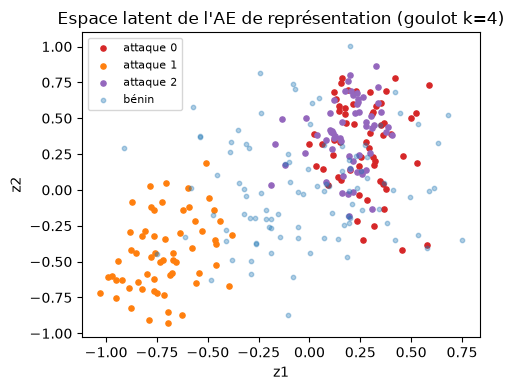

In [10]:
# Demo 5 — latent embeddings + cosine k-NN family attribution
def embed(X, P):
    """Bottleneck activation z = E(x) : the representation used for similarity."""
    _, (_, z, _) = ae_forward(X, P)
    return z

def cosine_sim(A, B):
    An = A / np.linalg.norm(A, axis=1, keepdims=True)
    Bn = B / np.linalg.norm(B, axis=1, keepdims=True)
    return An @ Bn.T

# reference base (labeled attacks) and QUERIES drawn from disjoint indices
# Representation neck WIDER than the detection neck: k=4 keeps enough signal
# to separate attack families, while the k=2 detection neck stays for scoring.
P_rep = ae_train(Xben, d=8, h=8, k=4, epochs=1200, seed=1)
Z_ref = embed(Xatk, P_rep)
lab_ref = labatk.copy()
Z_query = Z_ref[:30]                       # queries...
Z_pool = Z_ref[30:]                        # ... excluded from the pool (no self-match)
lab_pool = lab_ref[30:]
S = cosine_sim(Z_query, Z_pool)
pred = lab_pool[np.argmax(S, axis=1)]
acc_knn = float((pred == lab_ref[:30]).mean())
print(f"k-NN cosinus sur le goulot (requêtes vs pool disjoint) : exactitude = {acc_knn:.3f}")
fig, ax = plt.subplots(figsize=(5, 4))
colors = ["tab:red", "tab:orange", "tab:purple"]
for fam in range(3):
    m = lab_ref == fam
    ax.scatter(Z_ref[m, 0], Z_ref[m, 1], s=14, c=colors[fam], label=f"attaque {fam}")
Zb = embed(Xben_test, P_rep)
ax.scatter(Zb[:, 0], Zb[:, 1], s=10, c="tab:blue", alpha=.35, label="bénin")
ax.set_xlabel("z1"); ax.set_ylabel("z2"); ax.legend(fontsize=8)
ax.set_title("Espace latent de l'AE de représentation (goulot k=4)"); fig.tight_layout(); plt.show()
assert acc_knn > 0.8, "les familles d'attaque forment des amas dans le latent"

### Exercice corrigé

**P5 — Cosinus à la main.** (a) Recalculez la similarité cosinus de deux
vecteurs du goulot avec la formule littérale et comparez à `cosine_sim` ;
(b) le plus proche voisin d'une requête de la famille 1 (hors elle-même) est
un membre de la famille 1.

In [11]:
# ---- Exercice P5 : cosinus littéral == cosine_sim ; voisin du même famille ----
zq = Z_ref[60]                     # un flux de la famille 1
za = Z_ref[100]                    # another flow of family 1
u, v = zq / np.linalg.norm(zq), za / np.linalg.norm(za)
cos_manual = float(u @ v)
S_pair = cosine_sim(zq[None, :], za[None, :])[0, 0]
assert np.isclose(cos_manual, S_pair, atol=1e-12), "cosinus littéral == cosine_sim"
S_full = cosine_sim(Z_ref, Z_ref)
np.fill_diagonal(S_full, -np.inf)
nn = int(np.argmax(S_full[60]))
print(f"cos manuel = {cos_manual:.6f} ; voisin le plus proche d'un flux famille 1 : "
      f"famille {lab_ref[nn]} (sim = {S_full[60, nn]:.4f})")
assert lab_ref[nn] == 1, "le NN d'un flux d'attaque est de sa famille"
print("Exercice P5 vérifié ✔")

cos manuel = 0.936705 ; voisin le plus proche d'un flux famille 1 : famille 1 (sim = 0.9993)
Exercice P5 vérifié ✔


## 6 · Cas cyber : détection d'anomalies sur flux réseau (AUC)

**Tâche complète, non supervisée :** on dispose uniquement de flux **bénins**
étiquetés. On entraîne l'AE sur le bénin, on score tout, on calibre le seuil
au quantile 95 % des bénins, et on évalue sur un jeu de test mélangeant
bénins et **trois familles d'attaque synthétiques** :

| Famille | Génération | Signature hors variété |
|---|---|---|
| ddos | décalage massif bytes_out | reconstruit très mal |
| portscan | motifs réguliers sur ports | hors variété bénigne |
| exfil | bursts sortants lents | hors variété bénigne |

Exigence : **AUC > 0.9** (graine figée, reproductible), matrice de confusion
au seuil calibré.

**Piège classique :** « entraîner sur tout le monde ». L'AE ne voit que le
bénin ; mélanger des attaques à l'entraînement lui apprendrait à les
reconstruire → score aveugle.

In [12]:
# Demo 6 — synthetic network flows: benign + 3 attack families, AE detector
# (Xben9 / Xatk / labatk were generated once at the top, standardized on benign stats)
P6 = ae_train(Xben9, d=8, h=5, k=2, epochs=600, seed=5)
sc_ben = anomaly_scores(Xben9, P6)
sc_atk = anomaly_scores(Xatk, P6)
seuil6 = np.quantile(sc_ben, 0.95)
y6 = np.r_[np.zeros(len(sc_ben)), np.ones(len(sc_atk))]
s6 = np.r_[sc_ben, sc_atk]
auc6 = roc_auc_score(y6, s6)
tp = int((sc_atk > seuil6).sum()); fp = int((sc_ben > seuil6).sum())
print(f"AE entraîné sur {len(sc_ben)} flux bénins seuls ; test : + {len(sc_atk)} attaques")
print(f"seuil (quantile 95 % bénin) = {seuil6:.5f}")
print(f"AUC = {auc6:.4f} ; alertes : VRAIES attaques = {tp}/180, fausses = {fp}/300")
per_fam = [float((sc_atk[labatk == f] > seuil6).mean()) for f in range(3)]
print("taux de détection par famille (ddos, portscan, exfil) :", np.round(per_fam, 3))
assert auc6 > 0.9, "le détecteur non supervisé doit dépasser AUC 0.9"
assert fp <= 30, "alertes à vide ≈ le seuil calibré (5 % de 300)"

AE entraîné sur 300 flux bénins seuls ; test : + 180 attaques
seuil (quantile 95 % bénin) = 0.64184
AUC = 1.0000 ; alertes : VRAIES attaques = 180/180, fausses = 15/300
taux de détection par famille (ddos, portscan, exfil) : [1. 1. 1.]


**Lecture.** Les trois familles sont vues **sans avoir été jamais étiquetées**
à l'entraînement : c'est la force du paradigme « apprendre le normal, tout
le reste est anomalie » quand les attaques manquent (le cas réel du SOC).

### Exercice corrigé

**P6 — Stabilité du détecteur.** Sur la même architecture et une **graine
différente** (n=40/bénin, attaques différentes), l'AUC doit rester > 0.9 ;
vérifiez aussi qu'un AE entraîné **avec les attaques mélangées** devient
aveugle (AUC effondrée < 0.8) — la leçon du piège.

In [13]:
# ---- Exercice P6 : stabilité AUC > 0.9 + AE contaminé = aveugle ----
rng = np.random.default_rng(202)
Xatk_b, lab_b = make_attacks(rng, 40)
Xben_b = make_benign(rng, 240)
mu_b, sd_b = Xben_b.mean(0), Xben_b.std(0)
Xben_b = (Xben_b - mu_b) / sd_b
Xatk_b = (Xatk_b - mu_b) / sd_b
P_clean = ae_train(Xben_b, d=8, h=5, k=2, epochs=600, seed=8)
sc_b = anomaly_scores(Xben_b, P_clean); sc_a = anomaly_scores(Xatk_b, P_clean)
auc_b = roc_auc_score(np.r_[np.zeros(len(sc_b)), np.ones(len(sc_a))],
                      np.r_[sc_b, sc_a])
# contaminated training (the classic trap) : AE learns to rebuild attacks too
P_dirty = ae_train(np.vstack([Xben_b, Xatk_b]), d=8, h=5, k=2, epochs=600, seed=9)
sc_b2 = anomaly_scores(Xben_b, P_dirty); sc_a2 = anomaly_scores(Xatk_b, P_dirty)
auc_dirty = roc_auc_score(np.r_[np.zeros(len(sc_b2)), np.ones(len(sc_a2))],
                          np.r_[sc_b2, sc_a2])
print(f"AE propre (bénin seul) : AUC = {auc_b:.4f}")
print(f"AE contaminé (bénin+attaques) : AUC = {auc_dirty:.4f}")
assert auc_b > 0.9, "stabilité : AUC > 0.9 sur une autre graine"
assert auc_dirty < auc_b - 0.05, "contaminer l'entraînement aveugle le détecteur"
print("Exercice P6 vérifié ✔")

AE propre (bénin seul) : AUC = 1.0000
AE contaminé (bénin+attaques) : AUC = 0.6921
Exercice P6 vérifié ✔


## 7 · Synthèse globale — l'essentiel & exemple intégrateur

### Ce qu'il faut retenir (les 6 points)

| # | Point | L'essentiel |
|---|---|---|
| 1 | Architecture | encodeur → **goulot k** → décodeur ; MSE(x̂,x) ; goulot étroit = représentation |
| 2 | AE linéaire = PCA | sous-espace = top-k composantes principales (cosinus > 0.99) |
| 3 | Denoising | entrée corrompue → cible propre ; régularise et débruite (× gain) |
| 4 | Score anomalie | `‖x−x̂‖²`, seuil = **quantile des bénins**, AUC indépendante du seuil |
| 5 | Latent & k-NN | `z = E(x)` + cosinus normalisé → familles d'attaques regroupées |
| 6 | Cas cyber | AE entraîné **sur le bénin seul**, AUC > 0.9 sur attaques jamais vues |

**Exemple intégrateur — détecteur non supervisé complet.** Pipeline bout-en-bout :
(1) **score** d'anomalie → (2) **seuil** calibré sur le bénin →
(3) flux signalés **embarqués** dans le goulot et rattachés par **k-NN cosinus**
à une famille d'attaque de référence (base étiquetée séparée, disponible après
coup). C'est le schéma réel : détection *non supervisée* le jour J,
qualification *supervisée* quand la menace apparaît.

détection : 168 flux signalés / 350 ; AUC pipeline = 1.0000
qualification k-NN des attaques signalées : exactitude famille = 1.000


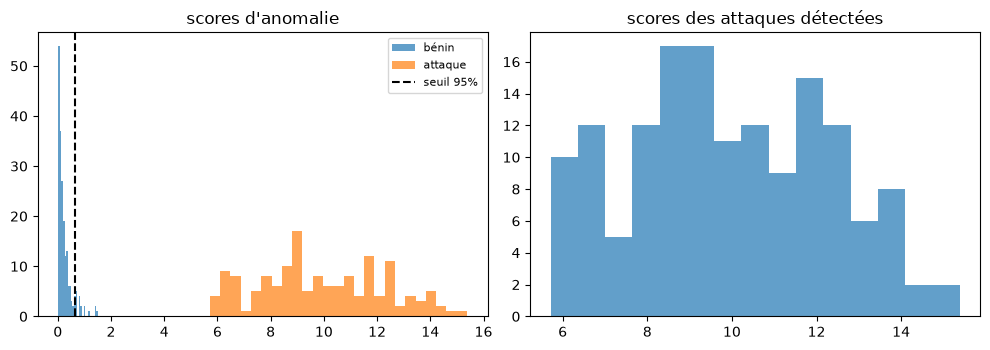

In [14]:
# Integrator 7 — full pipeline: score -> threshold -> latent k-NN attribution
# a fresh mixed capture (new seed => unseen instance)
rng7 = np.random.default_rng(303)
Xatk7, lab7 = make_attacks(rng7, 50)
Xben7 = make_benign(rng7, 200)
Xatk7 = (Xatk7 - mu9) / sd9                                  # frozen benign stats
Xben7 = (Xben7 - mu9) / sd9
Xmix = np.vstack([Xben7, Xatk7]); ymix = np.r_[np.zeros(len(Xben7)), np.ones(len(Xatk7))]
scores7 = anomaly_scores(Xmix, P6)
seuil7 = np.quantile(anomaly_scores(Xben9, P6), 0.95)        # threshold from benign only
flagged = scores7 > seuil7
auc7 = roc_auc_score(ymix, scores7)
# qualification of the flagged ATTACKS by k-NN against a labeled reference base
idx_flag = np.where(flagged & (ymix == 1))[0]               # rows in the attack block
Z_ref7 = embed(Xatk, P_rep)                                   # reference (labeled attacks)
Z_flag = embed(Xmix[idx_flag], P_rep)
S7 = cosine_sim(Z_flag, Z_ref7)
pred_fam = lab_ref[np.argmax(S7, axis=1)]
true_fam = lab7[idx_flag - len(Xben7)]                 # lab7 indexes attacks only
acc_attr = float((pred_fam == true_fam).mean())
print(f"détection : {int(flagged.sum())} flux signalés / {len(ymix)} ; AUC pipeline = {auc7:.4f}")
print(f"qualification k-NN des attaques signalées : exactitude famille = {acc_attr:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(scores7[ymix == 0], bins=25, alpha=.7, label="bénin")
ax[0].hist(scores7[ymix == 1], bins=25, alpha=.7, label="attaque")
ax[0].axvline(seuil7, color="k", ls="--", label="seuil 95%")
ax[0].set_title("scores d'anomalie"); ax[0].legend(fontsize=8)
ax[1].hist(scores7[flagged & (ymix == 1)], bins=15, alpha=.7)
ax[1].set_title("scores des attaques détectées")
fig.tight_layout(); plt.show()
assert auc7 > 0.9, "le pipeline complet reste > AUC 0.9"
assert acc_attr > 0.8, "la qualification des alertes est fiable > 0.8"

### Exercice corrigé

**P7 — Contrôle du pipeline.** Sur une capture fraîche (graine 404),
vérifiez : (a) AUC du pipeline > 0.9 ; (b) les **30 pires scores** sont
tous des attaques (précision 100 % sur le top-30 des alertes) ; (c) le taux
d'alerte à vide sur le bénin ≤ 10 %.

In [15]:
# ---- Exercice P7 : pipeline complet sur capture fraîche — top-30 et FPR ----
rng8 = np.random.default_rng(404)
Xatk8, lab8 = make_attacks(rng8, 50)
Xben8 = make_benign(rng8, 200)
Xatk8 = (Xatk8 - mu9) / sd9
Xben8 = (Xben8 - mu9) / sd9
Xmix8 = np.vstack([Xben8, Xatk8]); ymix8 = np.r_[np.zeros(len(Xben8)), np.ones(len(Xatk8))]
sc8 = anomaly_scores(Xmix8, P6)
auc8 = roc_auc_score(ymix8, sc8)
top30 = np.argsort(sc8)[-30:]
prec_top30 = float((ymix8[top30] == 1).mean())
fpr8 = float(((sc8 > seuil7) & (ymix8 == 0)).mean())
print(f"AUC (capture fraîche) = {auc8:.4f} ; précision top-30 = {prec_top30:.3f} ; "
      f"alerte à vide = {fpr8:.3f}")
assert auc8 > 0.9
assert prec_top30 == 1.0, "les 30 pires scores sont bien 30 attaques"
assert fpr8 <= 0.10
print("Exercice P7 vérifié ✔")

print("NB 06 — tous les exercices sont vérifiés. ✅")
print("06_autoencodeurs_anomalies — exercices vérifiés. ✅")

AUC (capture fraîche) = 1.0000 ; précision top-30 = 1.000 ; alerte à vide = 0.046


Exercice P7 vérifié ✔
NB 06 — tous les exercices sont vérifiés. ✅
06_autoencodeurs_anomalies — exercices vérifiés. ✅
